# Downloading the Data

In [ ]:
medical_charges_url="https://raw.githubusercontent.com/JovianML/opendatasets/master/data/medical-charges.csv"

In [ ]:
from urllib.request import urlretrieve

In [ ]:
urlretrieve(medical_charges_url,"medical.csv")

('medical.csv', <http.client.HTTPMessage at 0x7d357e4bd460>)

In [ ]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import  seaborn as sns
%matplotlib inline

In [ ]:
medical_df=pd.read_csv("medical.csv")

In [ ]:
medical_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [ ]:
medical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
medical_df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
!pip install jovian --quiet
import jovian
jovian.commit

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 1.7 MB/s eta 0:00:00


<function jovian.utils.commit.commit(message=None, files=[], outputs=[], environment=None, privacy='auto', filename=None, project=None, new_project=None, git_commit=False, git_message='auto', require_write_access=False, **kwargs)>

# Exploratory Analysis and Visualiation

In [ ]:
sns.set_style("darkgrid")
matplotlib.rcParams["font.size"]=14
matplotlib.rcParams["figure.figsize"]=(10,6)
matplotlib.rcParams["figure.facecolor"]="#00000000"


#Age

In [ ]:
medical_df.age.describe()

,age
count,1338.000000
mean,39.207025
std,14.049960
min,18.000000
25%,27.000000
50%,39.000000
75%,51.000000
max,64.000000


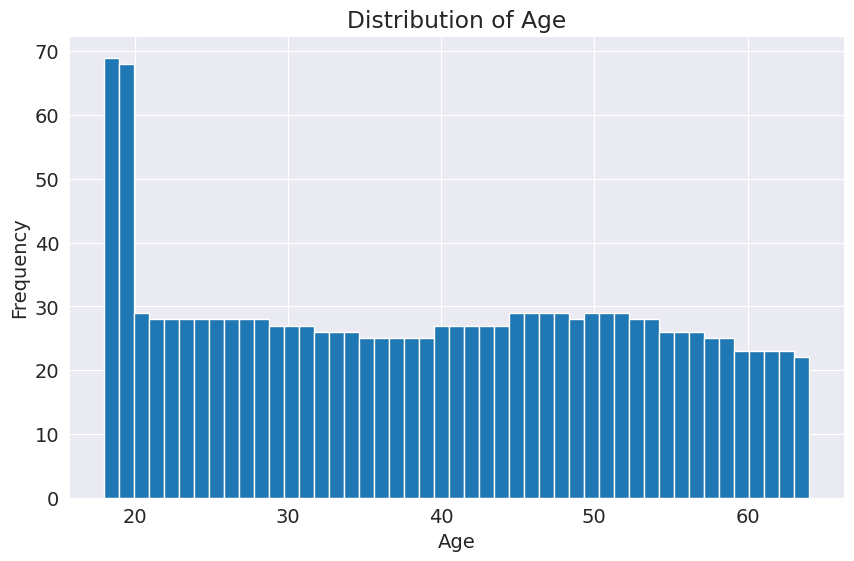

In [ ]:
plt.hist(data=medical_df,x="age",bins=47)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")
plt.show()

Body mass index

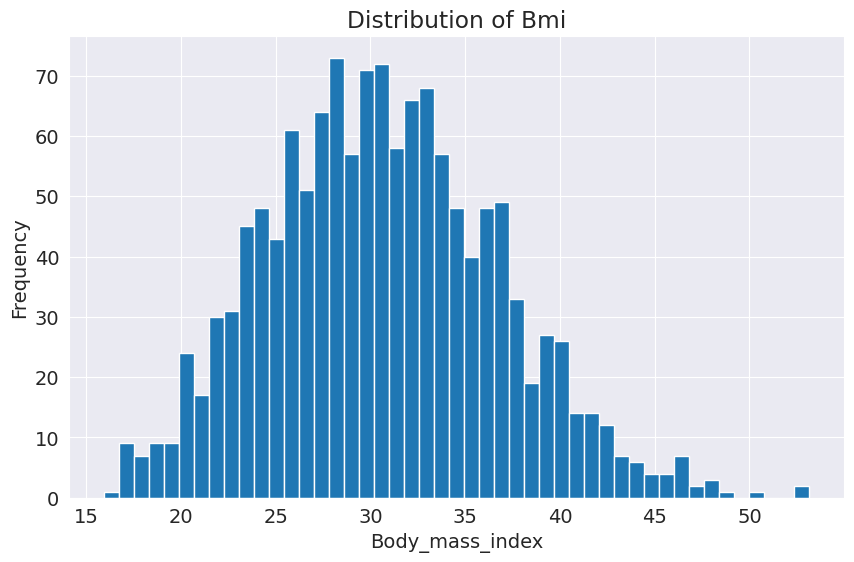

In [ ]:
plt.hist(data=medical_df,x="bmi",bins=47)
plt.xlabel("Body_mass_index")
plt.ylabel("Frequency")
plt.title("Distribution of Bmi")
plt.show()

charges

<Axes: xlabel='charges', ylabel='Count'>

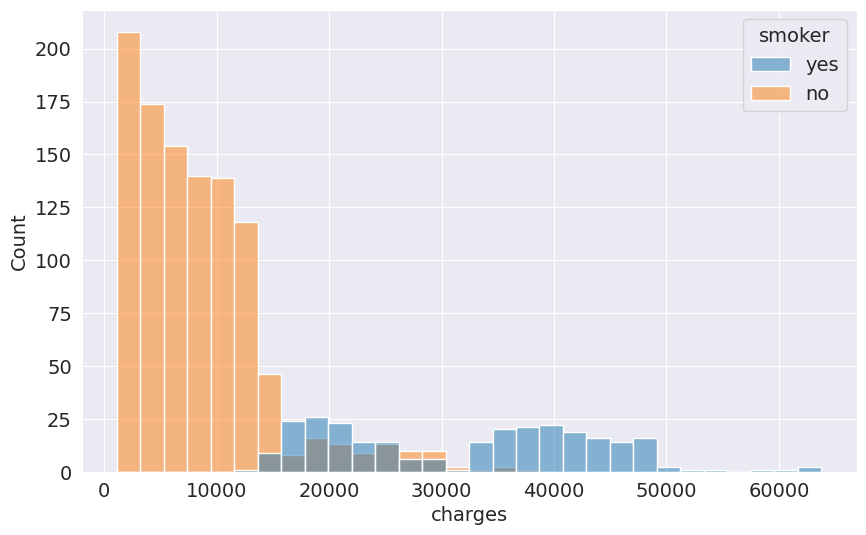

In [ ]:
sns.histplot(data=medical_df,x="charges",hue="smoker")

Text(0.5, 1.0, 'Distribution of smokers')

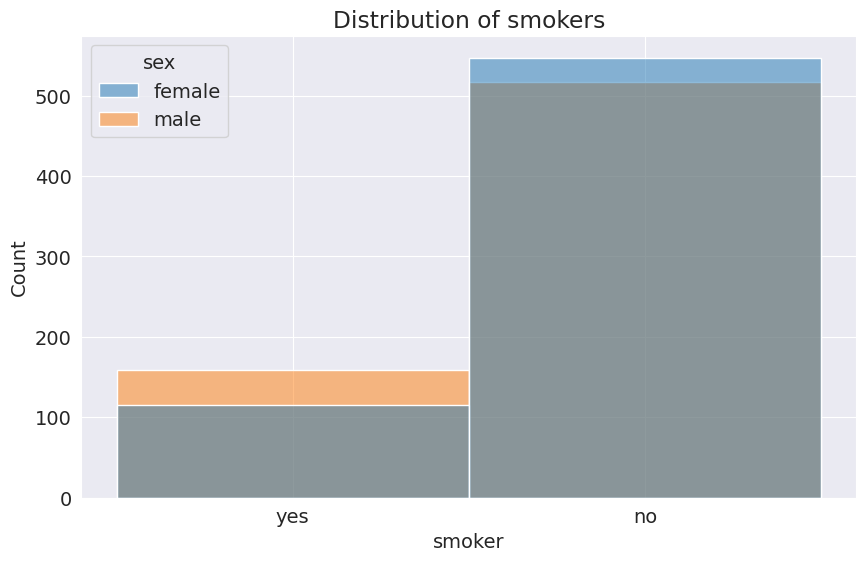

In [ ]:
sns.histplot(data=medical_df,x="smoker",hue="sex")
plt.title("Distribution of smokers")



Age and Charges



Text(0.5, 1.0, 'Age vs Charges')

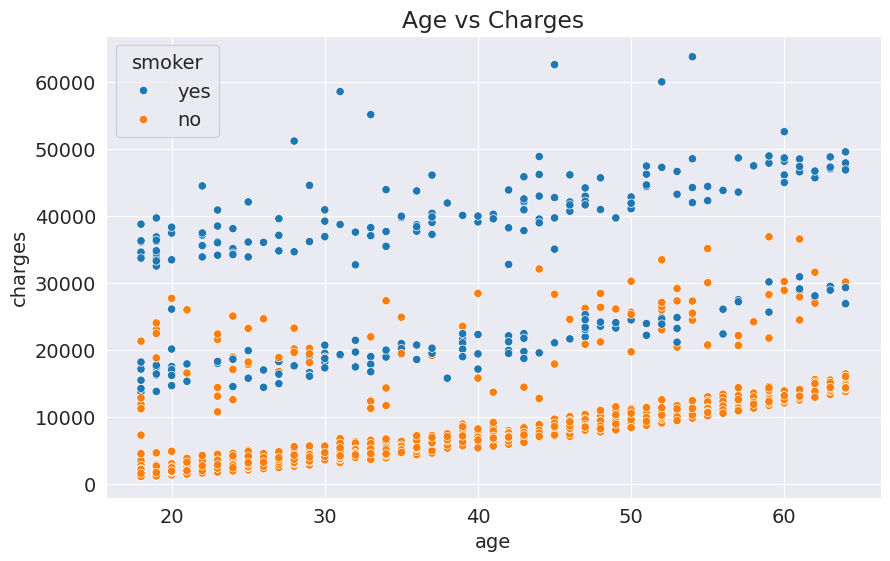

In [ ]:
sns.scatterplot(data=medical_df,x="age",y="charges",hue="smoker")
plt.title("Age vs Charges")

# Correlation

In [ ]:
medical_df["charges"].corr(medical_df["age"])

np.float64(0.2990081933306476)

In [ ]:
medical_df["charges"].corr(medical_df["bmi"])

np.float64(0.19834096883362895)

to check correlation for a categorical column u will  firstly convert it to numerical column

In [ ]:
smokers_value={
    "no":0,
    "yes":1
}
smoker_numerical=medical_df.smoker.map(smokers_value)
medical_df.charges.corr(smoker_numerical)
medical_df["smoker_numerical"]=smoker_numerical

In [ ]:
medical_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1338 non-null   int64  
 1   sex               1338 non-null   object 
 2   bmi               1338 non-null   float64
 3   children          1338 non-null   int64  
 4   smoker            1338 non-null   object 
 5   region            1338 non-null   object 
 6   charges           1338 non-null   float64
 7   smoker_numerical  1338 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 83.8+ KB


In [ ]:
numerical_columns=["age","bmi","children","charges","smoker_numerical"]

medical_df[numerical_columns].corr()

,age,bmi,children,charges,smoker_numerical
age,1.000000,0.109272,0.042469,0.299008,-0.025019
bmi,0.109272,1.000000,0.012759,0.198341,0.003750
children,0.042469,0.012759,1.000000,0.067998,0.007673
charges,0.299008,0.198341,0.067998,1.000000,0.787251
smoker_numerical,-0.025019,0.003750,0.007673,0.787251,1.000000


<Axes: >

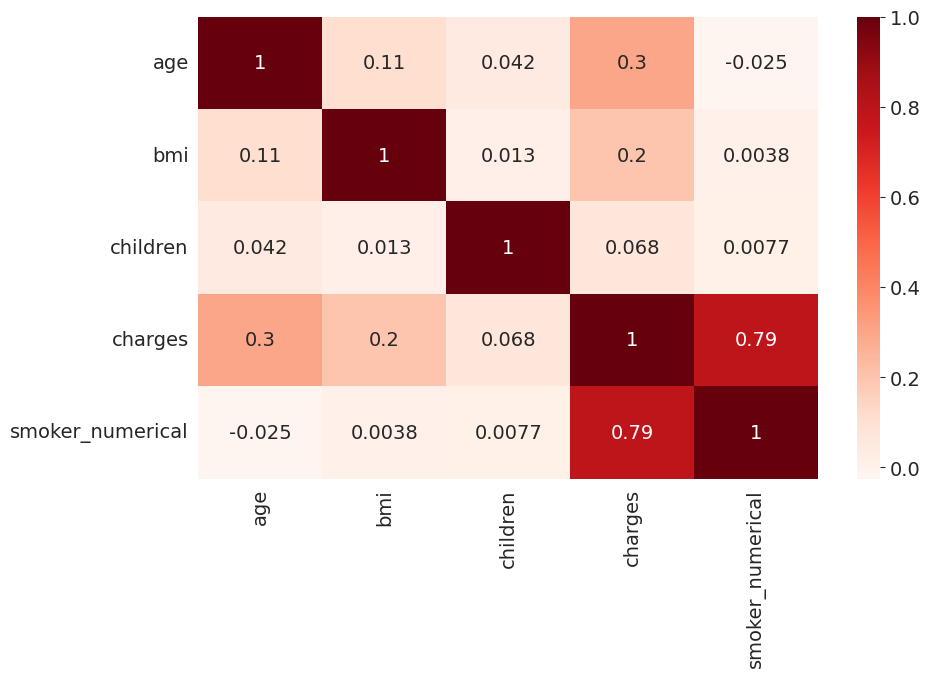

In [ ]:
sns.heatmap(medical_df[numerical_columns].corr() ,cmap="Reds" ,annot=True)

# Linear Regression Using A single Feature

In [ ]:
non_smoker_df=medical_df[medical_df.smoker=="no"]
non_smoker_df.head(10)


,age,sex,bmi,children,smoker,region,charges,smoker_numerical
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0
5,31,female,25.740,0,no,southeast,3756.62160,0
6,46,female,33.440,1,no,southeast,8240.58960,0
7,37,female,27.740,3,no,northwest,7281.50560,0
8,37,male,29.830,2,no,northeast,6406.41070,0
9,60,female,25.840,0,no,northwest,28923.13692,0
10,25,male,26.220,0,no,northeast,2721.32080,0


In [ ]:
from scipy import stats
result=stats.linregress(non_smoker_df['age'],non_smoker_df['charges'])
result

LinregressResult(slope=np.float64(267.2489128311995), intercept=np.float64(-2091.420556565079), rvalue=np.float64(0.6279467837664193), pvalue=np.float64(9.1720181333733e-118), stderr=np.float64(10.163738484459296), intercept_stderr=np.float64(425.102040878521))

<Axes: title={'center': 'Age vs  charges'}, xlabel='age', ylabel='charges'>

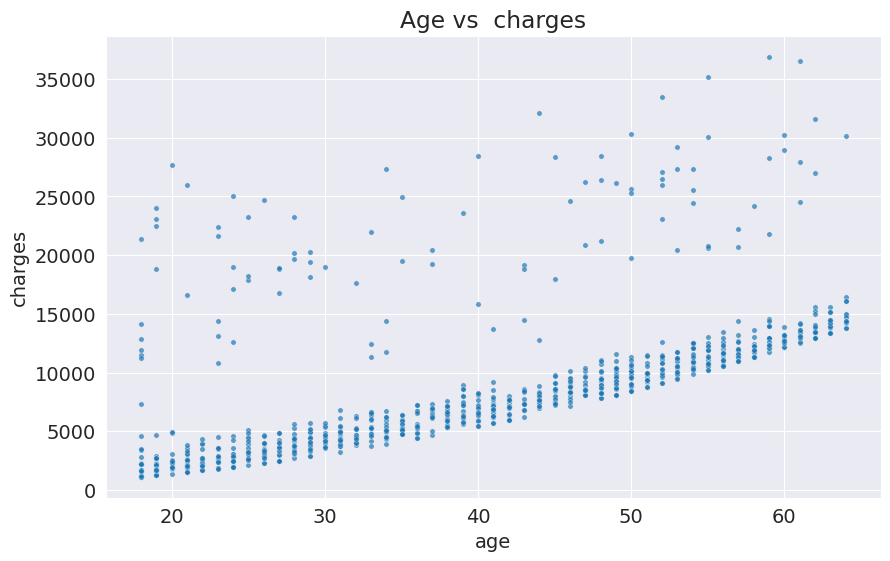

In [ ]:
plt.title("Age vs  charges")
sns.scatterplot(data=non_smoker_df,x="age",y="charges",alpha=0.7,s=15)

In [ ]:
def estimate_charges(m,age,c):
  charges= m *age + c
  return charges
m=261
c=-2092
estimate_charges(m,20,c)


3128

In [ ]:
ages=non_smoker_df.age
ages

,age
1,18
2,28
3,33
4,32
5,31
...,...
1332,52
1333,50
1334,18
1335,18


In [ ]:
estimated_charges=estimate_charges(ages,m,c)
estimated_charges

,age
1,2606
2,5216
3,6521
4,6260
5,5999
...,...
1332,11480
1333,10958
1334,2606
1335,2606


In [ ]:
non_smoker_df["estimated_charges"]=estimated_charges
non_smoker_df[["estimated_charges","charges"]].sample(20)

/tmp/ipykernel_1131/3704506480.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_smoker_df["estimated_charges"]=estimated_charges


,estimated_charges,charges
219,4172,25081.76784
1009,11219,9957.72160
22,2606,1137.01100
264,11741,20462.99766
957,4172,12609.88702
658,10436,26392.26029
976,10436,7804.16050
177,12002,10436.09600
339,9914,8232.63880
807,2867,2136.88225


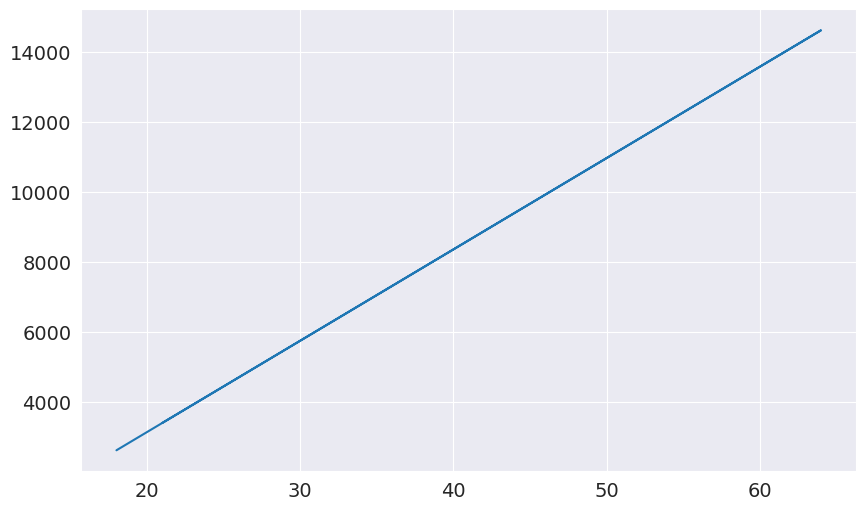

In [ ]:
plt.plot(ages,estimated_charges,label="estimated_charges")


In [ ]:
non_smoker_df.head(10)

,age,sex,bmi,children,smoker,region,charges,smoker_numerical,estimated_charges
1,18,male,33.770,1,no,southeast,1725.55230,0,2606
2,28,male,33.000,3,no,southeast,4449.46200,0,5216
3,33,male,22.705,0,no,northwest,21984.47061,0,6521
4,32,male,28.880,0,no,northwest,3866.85520,0,6260
5,31,female,25.740,0,no,southeast,3756.62160,0,5999
6,46,female,33.440,1,no,southeast,8240.58960,0,9914
7,37,female,27.740,3,no,northwest,7281.50560,0,7565
8,37,male,29.830,2,no,northeast,6406.41070,0,7565
9,60,female,25.840,0,no,northwest,28923.13692,0,13568
10,25,male,26.220,0,no,northeast,2721.32080,0,4433


In [ ]:
non_smoker_df.drop(["smoker_numerical"],axis= 1)

,age,sex,bmi,children,smoker,region,charges,estimated_charges
1,18,male,33.770,1,no,southeast,1725.55230,2606
2,28,male,33.000,3,no,southeast,4449.46200,5216
3,33,male,22.705,0,no,northwest,21984.47061,6521
4,32,male,28.880,0,no,northwest,3866.85520,6260
5,31,female,25.740,0,no,southeast,3756.62160,5999
...,...,...,...,...,...,...,...,...
1332,52,female,44.700,3,no,southwest,11411.68500,11480
1333,50,male,30.970,3,no,northwest,10600.54830,10958
1334,18,female,31.920,0,no,northeast,2205.98080,2606
1335,18,female,36.850,0,no,southeast,1629.83350,2606


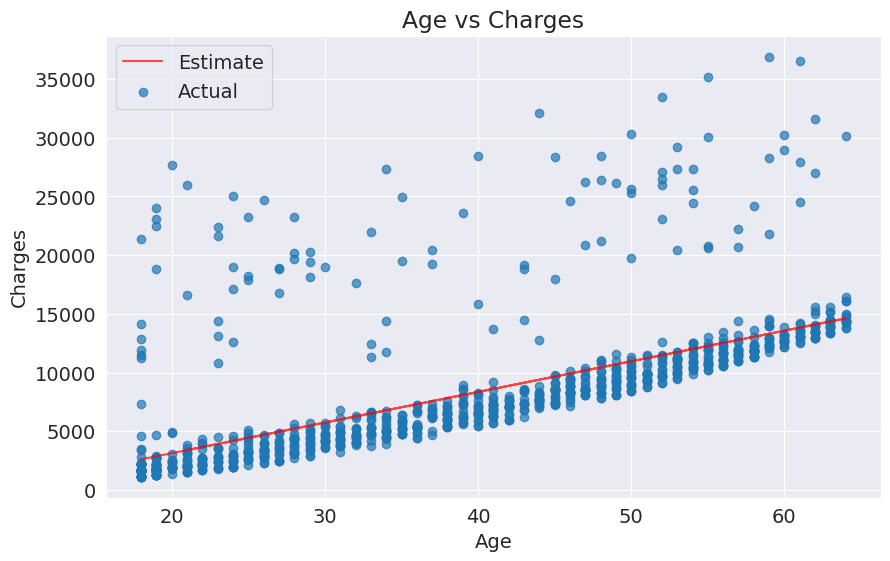

In [ ]:
def try_different_parameters(m,c):
  ages=non_smoker_df.age
  target=non_smoker_df.charges
  estimated_charges=estimate_charges(ages,m,c)
  plt.plot(ages,estimated_charges,"r",alpha=0.7)
  plt.scatter(ages,target,alpha=0.7)
  plt.xlabel("Age")
  plt.ylabel("Charges")
  plt.title("Age vs Charges")
  plt.legend(["Estimate","Actual"])
try_different_parameters(261,-2092)

# Linear regression with scikit_learn

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np


In [ ]:
model=LinearRegression()

In [ ]:
help(model.fit)

Help on method fit in module sklearn.linear_model._base:

fit(X, y, sample_weight=None) method of sklearn.linear_model._base.LinearRegression instance
    Fit linear model.

    Parameters
    ----------
    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        Training data.

    y : array-like of shape (n_samples,) or (n_samples, n_targets)
        Target values. Will be cast to X's dtype if necessary.

    sample_weight : array-like of shape (n_samples,), default=None
        Individual weights for each sample.

        .. versionadded:: 0.17
           parameter *sample_weight* support to LinearRegression.

    Returns
    -------
    self : object
        Fitted Estimator.



ur input variable x should be in 2 dimmension(dataframe) while ur y variable should be in 1 dimension (series)

In [ ]:
inputs=non_smoker_df[["age"]]
targets=non_smoker_df["charges"]
print("inputs.shape", inputs.shape)
print("targets.shape", targets.shape)


inputs.shape (1064, 1)
targets.shape (1064,)


In [ ]:
model.fit(inputs,targets)

LinearRegression()

In [ ]:
err5model.predict(np.array([[23],[37],[61]]))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([ 4055.30443855,  7796.78921819, 14210.76312614])

In [ ]:
prediction= model.predict(inputs)

In [ ]:
prediction

array([2719.0598744 , 5391.54900271, 6727.79356686, ..., 2719.0598744 ,
       2719.0598744 , 3520.80661289])

In [ ]:
targets

,charges
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520
5,3756.62160
...,...
1332,11411.68500
1333,10600.54830
1334,2205.98080
1335,1629.83350


In [ ]:

import numpy as np

def rmse(true_value, pred_value):
  return np.sqrt(np.mean(np.square(true_value - pred_value)))

rmse(targets,prediction)

np.float64(4662.505766636395)

 to find the sloe and intercept of the regression we use coef and intercept

In [ ]:
print(model.coef_)
model.intercept_

[267.24891283]


np.float64(-2091.4205565650864)

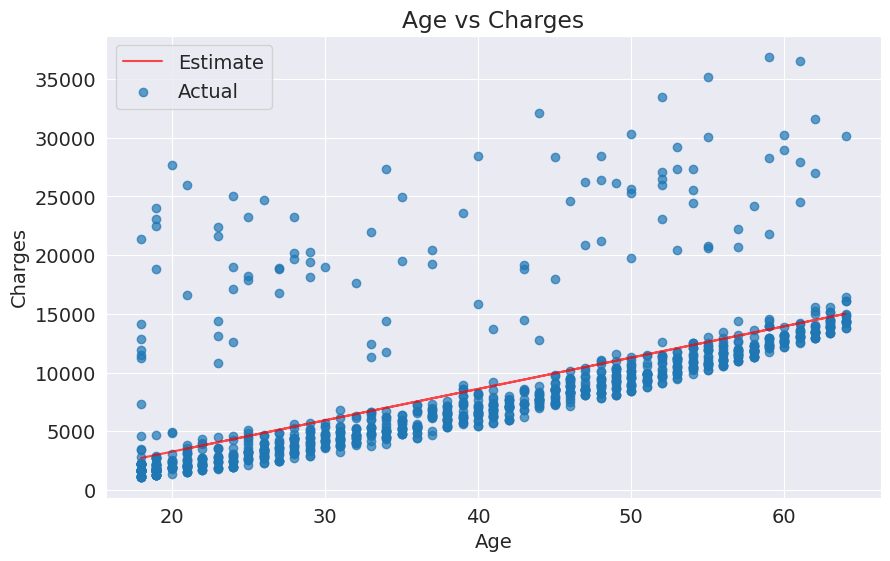

In [ ]:
try_different_parameters(model.coef_,model.intercept_)

the simple analogy it follows

In [ ]:
from sklearn.linear_model import LinearRegression
# create inputs and targes
inputs,targets=non_smoker_df[["age"]],non_smoker_df["charges"]
# create ande train model
model=LinearRegression().fit(inputs,targets)
# Generate  predictions
predictions=model.predict(inputs)
#compute loss to evaluate the model
loss=rmse(targets,predictions)
print('Loss',loss)

Loss 4662.505766636395


# Multiple linear regression
y=m1 x age + m2 x bmi + c

In [ ]:
inputs,targets=non_smoker_df[["age","bmi"]],non_smoker_df["charges"]
model=LinearRegression().fit(inputs,targets)
predictions=model.predict(inputs)
loss=rmse(targets,predictions)
print("loss",loss)
print(model.coef_)
print(model.intercept_)
print(predictions)

loss 4662.3128354612945
[266.87657817   7.07547666]
-2293.6320906488727
[2749.08516308 5412.40282772 6673.94368635 ... 2735.99553127 2770.87763119
 3493.32334862]


it seems like the cost function doesnt change that much after we add the bmi to the linear regression so we chect the correlation

In [ ]:
non_smoker_df.charges.corr(non_smoker_df.bmi)

np.float64(0.0840365431283327)

Text(0.5, 1.0, 'Bmi vs Charge')

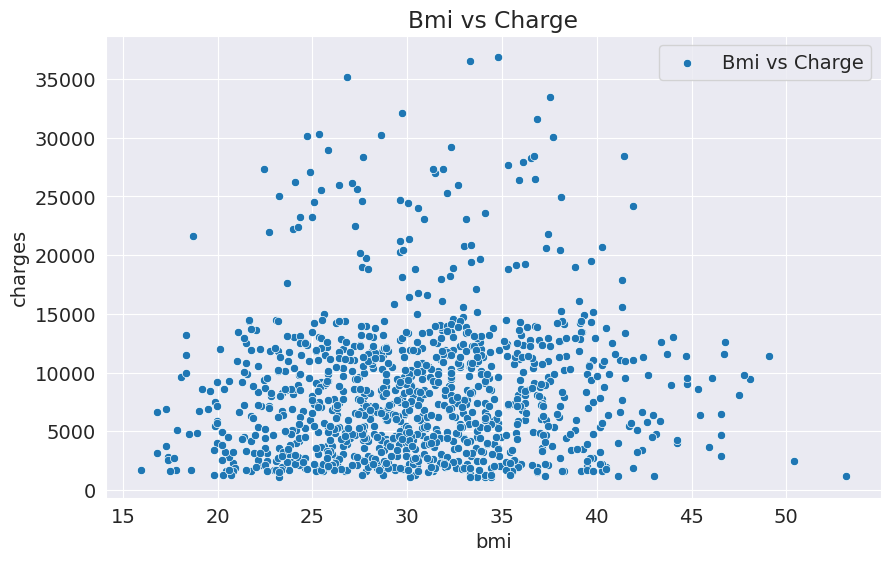

In [ ]:
sns.scatterplot(data=non_smoker_df,x="bmi",y="charges",label="Bmi vs Charge")
plt.title("Bmi vs Charge")
# there is almost no linear relationship  btw the data

# Using  Categorical Features for Machine Learning
for multiple linear regression the indpt columns can contains categorical and continous data

In [ ]:
medical_df.head(20)

,age,sex,bmi,children,smoker,region,charges,smoker_numerical
0,19,female,27.900,0,yes,southwest,16884.92400,1
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0
5,31,female,25.740,0,no,southeast,3756.62160,0
6,46,female,33.440,1,no,southeast,8240.58960,0
7,37,female,27.740,3,no,northwest,7281.50560,0
8,37,male,29.830,2,no,northeast,6406.41070,0
9,60,female,25.840,0,no,northwest,28923.13692,0


# binary category

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


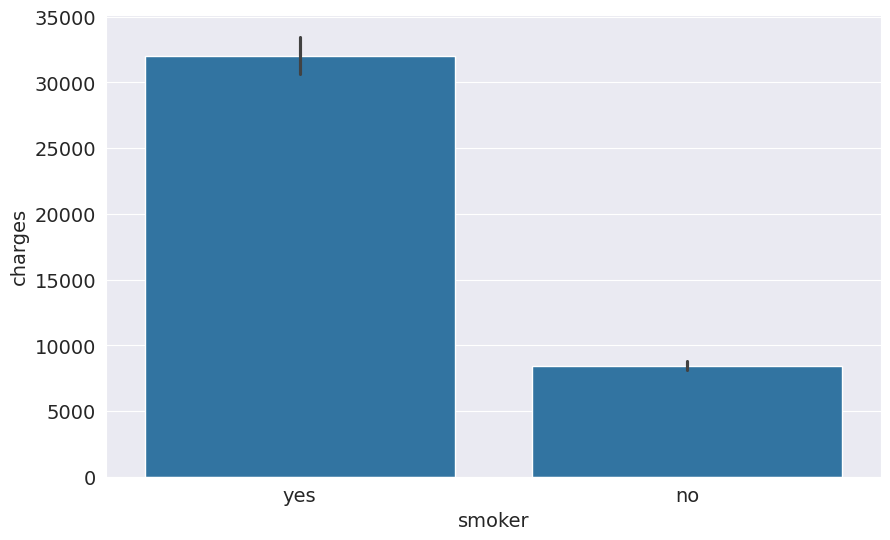

In [ ]:
sns.barplot(data=medical_df ,x="smoker",y="charges")
medical_df.drop(["smoker_numerical"],axis=1)


In [ ]:
smoker_codes={
    "no":0,
    "yes":1
}
medical_df["smoker_code"]=medical_df.smoker.map(smoker_codes)

In [ ]:
medical_df["charges"].corr(medical_df.smoker_code)

np.float64(0.787251430498478)

In [ ]:
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_numerical,smoker_code
0,19,female,27.900,0,yes,southwest,16884.92400,1,1
1,18,male,33.770,1,no,southeast,1725.55230,0,0
2,28,male,33.000,3,no,southeast,4449.46200,0,0
3,33,male,22.705,0,no,northwest,21984.47061,0,0
4,32,male,28.880,0,no,northwest,3866.85520,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,0
1334,18,female,31.920,0,no,northeast,2205.98080,0,0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0


lets create a multiple linear regression wher our independent variable are age,bmi,children,smoker_code to predict the charges

In [ ]:
input,targets=medical_df[["age","bmi","children","smoker_code"]],medical_df["charges"]
model=LinearRegression().fit(input,targets)
predictions=model.predict(input)
loss=rmse(targets,predictions)
print("loss",loss)
print(predictions)
medical_df["prediction"]=predictions

loss 6056.439217188081
[25587.42524891  3880.94594512  7158.62006921 ...  4398.7459491
  1615.83647369 36793.67069541]


In [ ]:
medical_df

,age,sex,bmi,children,smoker,region,charges,smoker_numerical,smoker_code,prediction
0,19,female,27.900,0,yes,southwest,16884.92400,1,1,25587.425249
1,18,male,33.770,1,no,southeast,1725.55230,0,0,3880.945945
2,28,male,33.000,3,no,southeast,4449.46200,0,0,7158.620069
3,33,male,22.705,0,no,northwest,21984.47061,0,0,3713.900470
4,32,male,28.880,0,no,northwest,3866.85520,0,0,5443.483373
...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,0,12177.950882
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,2812.018535
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,4398.745949
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,1615.836474


For sex

In [ ]:
sex_code={
    "male":1,
    "female":0
}
medical_df["sex_code"]=medical_df.sex.map(sex_code)
medical_df["charges"].corr(medical_df.sex_code)
# do the MPL
inputs,targets=medical_df[["age","bmi","children","smoker_code","sex_code"]],medical_df["charges"]
model=LinearRegression().fit(inputs,targets)
predictions=model.predict(inputs)
loss=rmse(targets,predictions)
print("loss",loss)
print(predictions)
medical_df["prediction"]=predictions
medical_df

loss 6056.100708754546
[25661.85689486  3818.77858262  7096.73025538 ...  4465.88909619
  1676.96948913 36863.89250792]


,age,sex,bmi,children,smoker,region,charges,smoker_numerical,smoker_code,prediction,sex_code
0,19,female,27.900,0,yes,southwest,16884.92400,1,1,25661.856895,0
1,18,male,33.770,1,no,southeast,1725.55230,0,0,3818.778583,1
2,28,male,33.000,3,no,southeast,4449.46200,0,0,7096.730255,1
3,33,male,22.705,0,no,northwest,21984.47061,0,0,3643.432244,1
4,32,male,28.880,0,no,northwest,3866.85520,0,0,5376.296281,1
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,0,12112.500629,1
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,2876.633519,0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,4465.889096,0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,1676.969489,0


# One hot encoding

<Axes: xlabel='region', ylabel='charges'>

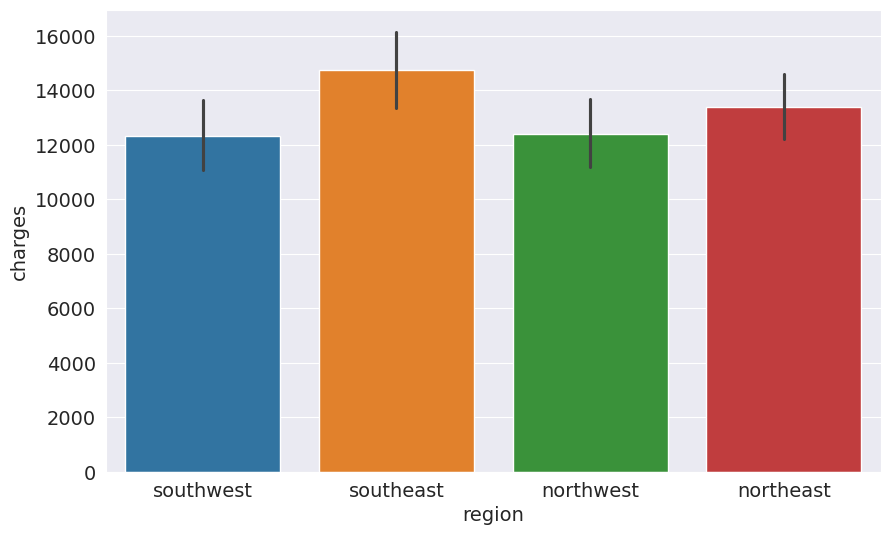

In [ ]:
sns.barplot(data=medical_df,x="region",y="charges",hue="region")

In [ ]:
from sklearn.preprocessing import OneHotEncoder
enc=OneHotEncoder()
enc.fit(medical_df[["region"]])
enc.categories_


[array(['northeast', 'northwest', 'southeast', 'southwest'], dtype=object)]

In [ ]:
enc

OneHotEncoder()

In [ ]:
one_hot=enc.transform(medical_df[["region"]]).toarray()
one_hot
one_hot1=pd.DataFrame(enc.transform(medical_df[["region"]]).toarray(), columns=enc.get_feature_names_out(['region']))
one_hot

array([[0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       ...,
       [0., 0., 1., 0.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.]])

let do for linear regression like that

In [ ]:
medical_df = pd.concat([medical_df, one_hot1], axis=1)

# create inputs and targets
inputs_cols=["age","bmi","children","smoker_code","sex_code","region_northeast","region_northwest","region_southeast","region_southwest"]
inputs,targets=medical_df[inputs_cols],medical_df["charges"]
# Create  and  train the model
model=LinearRegression().fit(inputs,targets)
# Generate predictions
predictions=model.predict(inputs)
# compute loss to evaluate the model
loss=rmse(targets,predictions)
print("loss",loss)
print(predictions)
medical_df["prediction"]=predictions
#commpare the predicted price to the actual price
medical_df

loss 6041.6796511744515
[25293.7130284   3448.60283431  6706.9884907  ...  4149.13248568
  1246.58493898 37085.62326757]


,age,sex,bmi,children,smoker,region,charges,smoker_numerical,smoker_code,prediction,sex_code,region_northeast,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,1,25293.713028,0,0.0,0.0,0.0,1.0
1,18,male,33.770,1,no,southeast,1725.55230,0,0,3448.602834,1,0.0,0.0,1.0,0.0
2,28,male,33.000,3,no,southeast,4449.46200,0,0,6706.988491,1,0.0,0.0,1.0,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,0,3754.830163,1,0.0,1.0,0.0,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,0,5592.493386,1,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,0,0,12351.323686,1,0.0,1.0,0.0,0.0
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,3511.930809,0,1.0,0.0,0.0,0.0
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,4149.132486,0,0.0,0.0,1.0,0.0
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,1246.584939,0,0.0,0.0,0.0,1.0


In [ ]:
medical_df[inputs_cols].loc[10]

,10
age,25.00
bmi,26.22
children,0.00
smoker_code,0.00
sex_code,1.00
region_northeast,1.00
region_northwest,0.00
region_southeast,0.00
region_southwest,0.00


In [ ]:
model.predict([[28,30,2,1,0,0,1,0,0]])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([29875.81463599])

In [ ]:
model.coef_,model.intercept_

(array([  256.85635254,   339.19345361,   475.50054515, 23848.53454191,
         -131.3143594 ,   587.00923503,   234.0453356 ,  -448.01281436,
         -373.04175627]),
 np.float64(-12525.547811195444))

# Model Improvement


In [ ]:
weights_df=pd.DataFrame({
    "feature":np.append(inputs_cols," Intercept"),
    "weight":np.append(model.coef_,model.intercept_)

})
weights_df


,feature,weight
0,age,256.856353
1,bmi,339.193454
2,children,475.500545
3,smoker_code,23848.534542
4,sex_code,-131.314359
5,region_northeast,587.009235
6,region_northwest,234.045336
7,region_southeast,-448.012814
8,region_southwest,-373.041756
9,Intercept,-12525.547811


# Create the table using standard Python list addition
weights_df = pd.DataFrame({
    "feature": list(inputs_cols) + ["Intercept"],
    "weight": list(model.coef_) + [model.intercept_]
})

weights_df

# Standardization

In [ ]:
numerical_columns=["age","bmi","children"]
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(medical_df[numerical_columns])

StandardScaler()

In [ ]:
scaler.mean_

array([39.20702541, 30.66339686,  1.09491779])

In [ ]:
scaler.var_


array([197.25385199,  37.16008997,   1.45212664])

In [ ]:
scaled_inputs= scaler.transform (medical_df[numerical_columns])
scaled_inputs

array([[-1.43876426, -0.45332   , -0.90861367],
       [-1.50996545,  0.5096211 , -0.07876719],
       [-0.79795355,  0.38330685,  1.58092576],
       ...,
       [-1.50996545,  1.0148781 , -0.90861367],
       [-1.29636188, -0.79781341, -0.90861367],
       [ 1.55168573, -0.26138796, -0.90861367]])

In [ ]:
scaled_inputs[0:,0]

array([-1.43876426, -1.50996545, -0.79795355, ..., -1.50996545,
       -1.29636188,  1.55168573])

In [ ]:
np.mean(scaled_inputs[ :,0])
# the result is in exponential

np.float64(-1.805564500436727e-16)

In [ ]:
np.round(np.mean(scaled_inputs[ :,0]),10)

np.float64(-0.0)

In [ ]:
medical_df.head(20)

,age,sex,bmi,children,smoker,region,charges,smoker_numerical,smoker_code,prediction,sex_code,region_northeast,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,1,25293.713028,0,0.0,0.0,0.0,1.0
1,18,male,33.770,1,no,southeast,1725.55230,0,0,3448.602834,1,0.0,0.0,1.0,0.0
2,28,male,33.000,3,no,southeast,4449.46200,0,0,6706.988491,1,0.0,0.0,1.0,0.0
3,33,male,22.705,0,no,northwest,21984.47061,0,0,3754.830163,1,0.0,1.0,0.0,0.0
4,32,male,28.880,0,no,northwest,3866.85520,0,0,5592.493386,1,0.0,1.0,0.0,0.0
5,31,female,25.740,0,no,southeast,3756.62160,0,0,3719.825799,0,0.0,0.0,1.0,0.0
6,46,female,33.440,1,no,southeast,8240.58960,0,0,10659.961225,0,0.0,0.0,1.0,0.0
7,37,female,27.740,3,no,northwest,7281.50560,0,0,8047.910607,0,0.0,1.0,0.0,0.0
8,37,male,29.830,2,no,northeast,6406.41070,0,0,8502.973920,1,1.0,0.0,0.0,0.0
9,60,female,25.840,0,no,northwest,28923.13692,0,0,11884.637518,0,0.0,1.0,0.0,0.0


In [ ]:
cat_cols=["smoker_code","sex_code","region_northeast","region_northwest","region_southeast","region_southwest"]
categorical_data=medical_df[cat_cols]

#  The multiple linear Regresion combining Standardscaler and oneHotEncoder

In [ ]:
input1=np.concatenate([scaled_inputs,categorical_data],axis=1)
input

,age,bmi,children,smoker_code
0,19,27.900,0,1
1,18,33.770,1,0
2,28,33.000,3,0
3,33,22.705,0,0
4,32,28.880,0,0
...,...,...,...,...
1333,50,30.970,3,0
1334,18,31.920,0,0
1335,18,36.850,0,0
1336,21,25.800,0,0


In [ ]:
inputs,targets=input1,medical_df["charges"]
# create and train the model
model=LinearRegression().fit(inputs,targets)
# generate predictions
predictions1=model.predict(inputs)
# compute the loss to evaluate the model
loss=rmse(targets,predictions1)
print("loss",loss)
print(predictions)
medical_df["prediction"]=predictions1
#
medical_df[["prediction","charges"]]

loss 6041.6796511744515
[25293.7130284   3448.60283431  6706.9884907  ...  4149.13248568
  1246.58493898 37085.62326757]


,prediction,charges
0,25293.713028,16884.92400
1,3448.602834,1725.55230
2,6706.988491,4449.46200
3,3754.830163,21984.47061
4,5592.493386,3866.85520
...,...,...
1333,12351.323686,10600.54830
1334,3511.930809,2205.98080
1335,4149.132486,1629.83350
1336,1246.584939,2007.94500


In [ ]:
# let check the slope  and intercpt  of the the model
print(model.coef_)
print(model.intercept_)
#
weights_df=pd.DataFrame({
    "feature":np.append(numerical_columns+cat_cols,"Intercept"),
    "weight":np.append(model.coef_,model.intercept_)
})
weights_df.sort_values("weight",ascending=False)
#
#


[ 3607.47273619  2067.69196584   572.99820995 23848.53454191
  -131.3143594    587.00923503   234.0453356   -448.01281436
  -373.04175627]
8466.48321541183


,feature,weight
3,smoker_code,23848.534542
9,Intercept,8466.483215
0,age,3607.472736
1,bmi,2067.691966
5,region_northeast,587.009235
2,children,572.998210
6,region_northwest,234.045336
4,sex_code,-131.314359
8,region_southwest,-373.041756
7,region_southeast,-448.012814


In [ ]:
# prediction for new customers
print(medical_df.loc[3])

age                          33
sex                        male
bmi                      22.705
children                      0
smoker                       no
region                northwest
charges             21984.47061
smoker_numerical              0
smoker_code                   0
prediction          3754.830163
sex_code                      1
region_northeast            0.0
region_northwest            1.0
region_southeast            0.0
region_southwest            0.0
Name: 3, dtype: object


In [ ]:
new_customer=np.array([[28,30,2,1,0,0,1,0,0]])

In [ ]:
scaler.transform([[28,30,2]])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[-0.79795355, -0.10882659,  0.75107928]])

In [ ]:
model.predict([[-0.79795355, -0.10882659,  0.75107928,1,0,0,1,0,0]])

array([29875.81463371])

# Creating a Test Set

In [ ]:
from sklearn.model_selection import train_test_split

i use certain percentage of ur data to train and use the other half to test if the model is good

In [ ]:
inputs_train,inputs_test,targets_train,targets_test=train_test_split(inputs,targets,test_size=0.1)



In [ ]:
# Create and train the model
model=LinearRegression().fit(inputs_train,targets_train)
# Generate prediction
predictions_test=model.predict(inputs_test)
loss=rmse(targets_test,predictions_test)
print("Test_loss",loss)

Test_loss 6309.828019024411


In [ ]:
# we used our the input train to predict the same data we use to train the model
# Generate predictions
prediction_train = model.predict(inputs_train)
loss_train = rmse(targets_train, prediction_train)
print("Train_loss",loss_train)
#

Train_loss 6014.475366977995
